# E0 — What is actually in the VAANI Malayalam subset?

A metadata audit of [`kurianbenoy/google-vaani-malayalam-subset`](https://huggingface.co/datasets/kurianbenoy/google-vaani-malayalam-subset): 10,000 utterances, about 15.4 hours, 892 identified speakers.

The question is not "how big is the corpus" but **which comparisons the corpus can support**. For every district, speaker and gender we count transcribed hours; for every transcript we count noise-event tags and English glosses.

In [1]:
import json
import re
from pathlib import Path

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from IPython.display import display

In [2]:
pd.set_option("display.width", 180)
pd.set_option("display.max_columns", 40)
pd.set_option("display.max_rows", 80)

REPO_ID = "kurianbenoy/google-vaani-malayalam-subset"
# Commit audited here. Bump deliberately: the revision is part of the result.
REVISION = "2b525ce2b4663cb0919dbccb143c4139bf74933c"

# Rule fixed before looking at results.
MIN_SPEAKERS = 5
MIN_MINUTES = 30.0


def find_project_root():
    for base in [Path.cwd(), *Path.cwd().parents]:
        if (base / "vaani_malayalam_10k_v2" / "manifest.jsonl").exists():
            return base
    return Path.cwd()


ROOT = find_project_root()
LOCAL_MANIFEST = ROOT / "vaani_malayalam_10k_v2" / "manifest.jsonl"
OUT_DIR = ROOT / "build" / "e0_audit"
OUT_DIR.mkdir(parents=True, exist_ok=True)

print("project root:", ROOT)
print("local manifest:", LOCAL_MANIFEST, "exists:", LOCAL_MANIFEST.exists())

project root: /home/kurian/interspeech-2027
local manifest: /home/kurian/interspeech-2027/vaani_malayalam_10k_v2/manifest.jsonl exists: True


In [3]:
if LOCAL_MANIFEST.exists():
    manifest_path = LOCAL_MANIFEST
    source = "local build"
else:
    from huggingface_hub import hf_hub_download

    manifest_path = Path(
        hf_hub_download(
            REPO_ID,
            "manifest.jsonl",
            repo_type="dataset",
            revision=REVISION,
        )
    )
    source = f"hub @ {REVISION[:8]}"

with open(manifest_path, encoding="utf-8") as f:
    records = [json.loads(line) for line in f if line.strip()]

df = pd.DataFrame(records).rename(
    columns={
        "speakerID": "speaker_id",
        "languagesKnown": "languages_known",
        "UtteranceSequenceID": "utterance_sequence_id",
        "source_file": "source_shard",
    }
)
df["duration_s"] = df["duration"].astype(float)
df["hours"] = df["duration_s"] / 3600
df["speaker_id"] = df["speaker_id"].fillna("UNKNOWN").astype(str)

print(f"loaded {len(df):,} rows from {source}")
print(f"audio: {df.hours.sum():.2f} h | districts: {df.district.nunique()} | "
      f"speakers: {df.loc[df.speaker_id != 'UNKNOWN', 'speaker_id'].nunique():,}")
df[["sample_id", "district", "gender", "speaker_id", "duration_s", "transcript"]].head(4)

loaded 10,000 rows from local build
audio: 15.37 h | districts: 11 | speakers: 892


,sample_id,district,gender,speaker_id,duration_s,transcript
0,0,Kasaragod,Male,UNKNOWN,4.118,<static> ആ ടാറിന് {tar} അപ്പുറം ചെറിയ ലാൻഡ്സ്ക...
1,1,Kasaragod,Male,UNKNOWN,4.085,<static> ചിത്രത്തിൽ ഒരാൾ ഒരു പുഴയുടെ കരയിൽ നിന...
2,2,Kasaragod,Male,UNKNOWN,4.622,<noise> ഇത് എവിടെയാണ് എന്ന് അറിയില്ല [breathin...
3,3,Kasaragod,Male,UNKNOWN,5.237,<static> ചിത്രത്തിൽ ആന്ധ്രപ്രദേശിലെ ഒരു ബസ് {b...


In [4]:
df.head()

,sample_id,audio_file,transcript,duration,speaker_id,gender,state,district,pincode,languages_known,isTranscriptionAvailable,referenceImage,speakerImageHash,utterance_sequence_id,duration_bin,source_shard,duration_s,hours
0,0,audio/00000.wav,<static> ആ ടാറിന് {tar} അപ്പുറം ചെറിയ ലാൻഡ്സ്ക...,4.118,UNKNOWN,Male,Kerala,Kasaragod,671122,[Malayalam],Yes,Images/IISc_VaaniProject_Kasaragod-SPECIFIC_00...,XM9N1QCZVKKHCC3VDWNIXDBFL3UAN0VARNI1AZ0L0GCPDW...,4,4–8s,audio/Malayalam/train-00016-of-00163.parquet,4.118,0.001144
1,1,audio/00001.wav,<static> ചിത്രത്തിൽ ഒരാൾ ഒരു പുഴയുടെ കരയിൽ നിന...,4.085,UNKNOWN,Male,Kerala,Kasaragod,671122,[Malayalam],Yes,Images/IISc_VaaniProject_GENERIC_1231.jpg,XM9N1QCZVKKHCC3VDWNIXDBFL3QB6RWTNO81DHVKMBCCZ,1,4–8s,audio/Malayalam/train-00016-of-00163.parquet,4.085,0.001135
2,2,audio/00002.wav,<noise> ഇത് എവിടെയാണ് എന്ന് അറിയില്ല [breathin...,4.622,UNKNOWN,Male,Kerala,Kasaragod,671122,[Malayalam],Yes,Images/IISc_VaaniProject_Kasaragod-SPECIFIC_01...,XM9N1QCZVKKHCC3VDWNIXDBFL3UAN0VARNI1AZ0L0GCPDW...,5,4–8s,audio/Malayalam/train-00016-of-00163.parquet,4.622,0.001284
3,3,audio/00003.wav,<static> ചിത്രത്തിൽ ആന്ധ്രപ്രദേശിലെ ഒരു ബസ് {b...,5.237,UNKNOWN,Male,Kerala,Kasaragod,671121,[Malayalam],Yes,Images/IISc_VaaniProject_GENERIC_0409.jpg,XM9N5MC2GKPWCCVX64PEBC87L3QB6RWTNO81DHUKPUDQF,1,4–8s,audio/Malayalam/train-00016-of-00163.parquet,5.237,0.001455
4,4,audio/00004.wav,<static> ഈ റൂം {room} ഒരു [vehicle_sound] എ_സി...,3.819,UNKNOWN,Male,Kerala,Kasaragod,671121,[Malayalam],Yes,Images/IISc_VaaniProject_Kasaragod-SPECIFIC_00...,XM9N5MC2GKPWCCVX64PEBC87L3UAN0VARNI1AZ0L0GCPDW...,4,<=4s,audio/Malayalam/train-00016-of-00163.parquet,3.819,0.001061


In [5]:
df["district"].value_counts()

district
Kasaragod             3000
Kollam                2167
Kozhikode             2142
Wayanad               1512
Thiruvananthapuram    1162
Belgaum                  7
Gulbarga                 3
Bangalore                3
Nalgonda                 2
Bellary                  1
Shimoga                  1
Name: count, dtype: int64

<Axes: xlabel='district'>

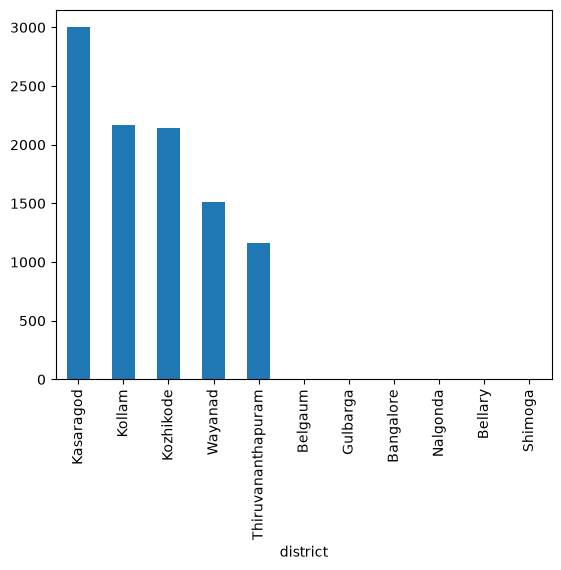

In [6]:
df["district"].value_counts().plot(kind='bar')

<Axes: xlabel='gender'>

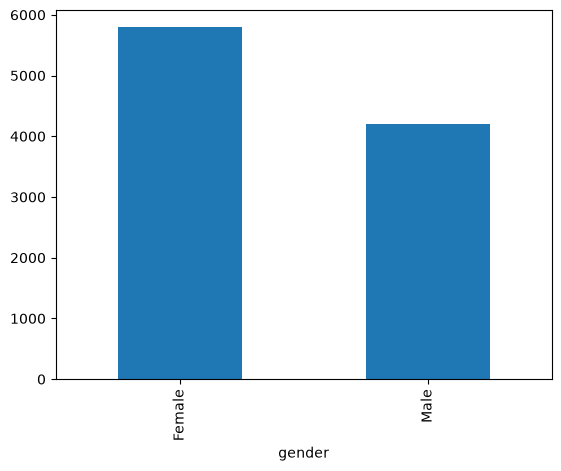

In [7]:
df['gender'].value_counts().plot(kind='bar')

In [8]:
df['pincode'].value_counts()

pincode
670645    486
671541    462
670646    369
671124    334
671321    280
         ... 
583134      1
577452      1
691557      1
691302      1
691560      1
Name: count, Length: 216, dtype: int64

191 pincodes have >= 5 records (9,941 of 10,000 rows)


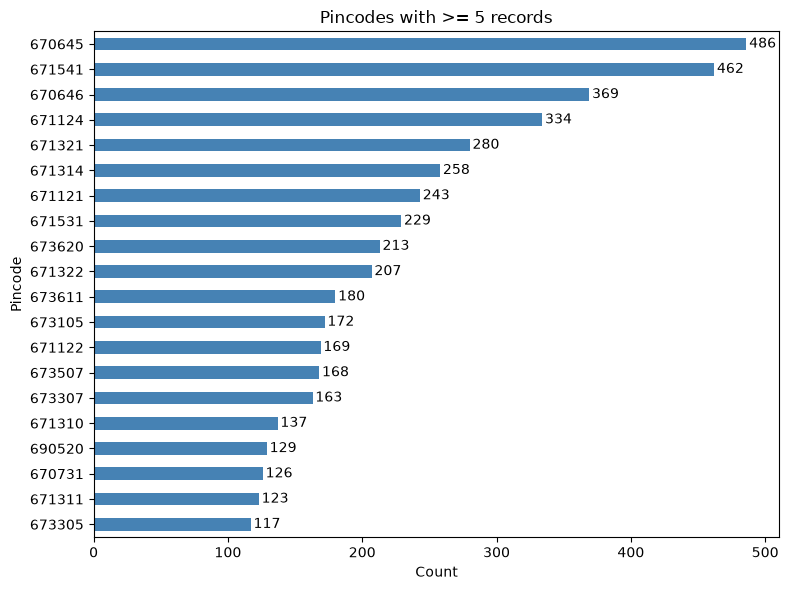

In [9]:
counts = df['pincode'].value_counts()
common = counts[counts >= 5].sort_values(ascending=False)

print(f"{len(common)} pincodes have >= 5 records "
      f"({common.sum():,} of {len(df):,} rows)")

# horizontal bars: sort ascending so the biggest ends up on top
ax = common.head(20).sort_values().plot.barh(
    figsize=(8, 6), color='steelblue', title='Pincodes with >= 5 records'
)
ax.set_xlabel('Count')
ax.set_ylabel('Pincode')
for c in ax.containers:
    ax.bar_label(c, padding=2)

plt.tight_layout()
plt.show()

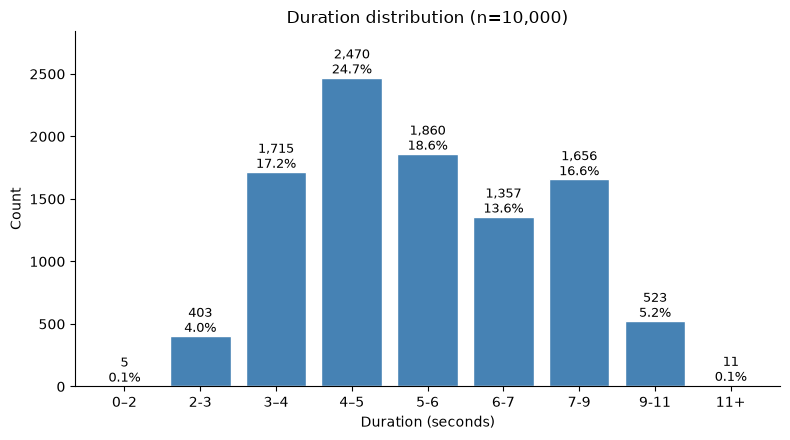

In [10]:
bins   = [0,2, 3, 4, 5, 6, 7, 9, 11, np.inf]
labels = ['0–2', '2-3', '3–4', '4–5', '5-6', '6-7', '7-9', '9-11', '11+']

dur = pd.to_numeric(df['duration'], errors='coerce')   # seconds
bucket = pd.cut(dur, bins=bins, labels=labels, right=False)

# reindex so empty bins still show up as zero-height bars
counts = bucket.value_counts().reindex(labels)

ax = counts.plot(
    kind='bar', rot=0, width=0.8, figsize=(8, 4.5),
    color='steelblue', edgecolor='white',
    title=f'Duration distribution (n={dur.notna().sum():,})',
)
ax.set_xlabel('Duration (seconds)')
ax.set_ylabel('Count')
ax.spines[['top', 'right']].set_visible(False)

total = len(dur)
for patch, v in zip(ax.patches, counts):
    ax.text(patch.get_x() + patch.get_width() / 2, v,
            f'{v:,}\n{v / total:.1%}',
            ha='center', va='bottom', fontsize=9)

ax.margins(y=0.15)
plt.tight_layout()
plt.savefig('duration_bins.png', dpi=300)
plt.show()

In [11]:
df["no_languages_know"] = df['languages_known'].apply(len)

[Text(0, 3, '5436'),
 Text(0, 3, '2598'),
 Text(0, 3, '1437'),
 Text(0, 3, '378'),
 Text(0, 3, '144'),
 Text(0, 3, '7')]

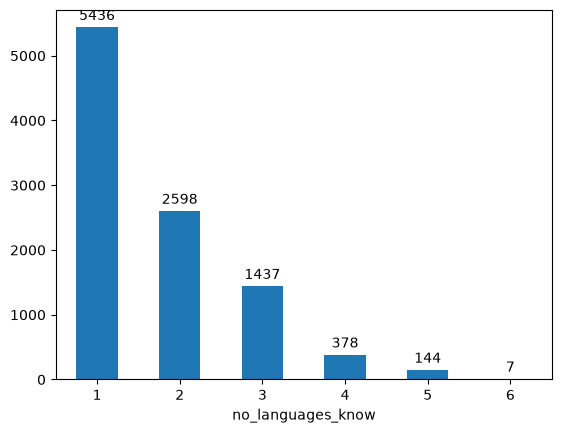

In [12]:
ax = df['no_languages_know'].value_counts().sort_index().plot(kind='bar', rot=0)
ax.bar_label(ax.containers[0], padding=3)      # actual count on top of each bar

In [13]:
BLUE = '#4C78A8'

In [14]:
def fancy_bar(series, title='', xlabel='', ylabel='Count', labels=None,
              color=BLUE, figsize=(8, 4.5), rot=0):
    """value_counts-style bar chart with the count printed on every bar."""
    ax = series.plot(kind='bar', rot=rot, width=0.75, figsize=figsize,
                     color=color, edgecolor='white', linewidth=0.8)
    ax.bar_label(ax.containers[0],
                 labels=labels if labels else [f'{v:,.0f}' for v in series.values],
                 padding=3, fontsize=9, color='#333333')

    ax.set_title(title, fontsize=12, fontweight='bold', pad=12)
    ax.set_xlabel(xlabel, fontsize=10)
    ax.set_ylabel(ylabel, fontsize=10)
    ax.tick_params(axis='x', labelsize=9)
    ax.spines[['top', 'right']].set_visible(False)   # drop the box
    ax.grid(axis='y', color='#e6e6e6', linewidth=0.8)
    ax.set_axisbelow(True)                           # grid behind bars
    ax.margins(y=0.14)                               # headroom for labels
    ax.figure.tight_layout()
    return ax

<Axes: title={'center': 'Languages known'}, xlabel='No. of languages', ylabel='Count'>

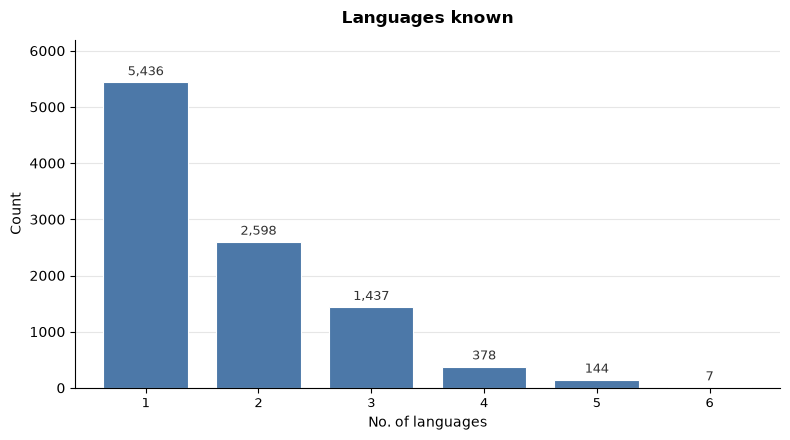

In [15]:
# 1. your languages chart
fancy_bar(df['no_languages_know'].value_counts().sort_index(),
          title='Languages known', xlabel='No. of languages')

## 1. Transcript grammar

Before counting tags, confirm what the tags actually are. The corpus mixes three things that look alike: segment markers (`<static>`), recording-condition labels (`<noise>`), and sound events (`[breathing]`, `<bird_sound>`). Counting them together would inflate the noise rate. The inventory below also shows why `{…}` must be split by script: 138 rows use braces for Malayalam corrections, not English.

In [16]:
TAG_RE = re.compile(r"<[^>]+>|\[[^\]]+\]")
BRACE_RE = re.compile(r"\{([^{}]*)\}")
ML_WORD_RE = re.compile(r"[\u0D00-\u0D7F]+")
LATIN_RE = re.compile(r"[A-Za-z]")

STRUCTURAL = {
    "static", "/static",
    "static_noise", "/static_noise",
    "noise", "/noise",
    "pause", "/pause",
}


def tag_name(tag):
    return tag[1:-1].strip()


def is_structural(tag):
    # Bracket tags are always events, even when the name matches "static".
    return tag.startswith("<") and tag_name(tag) in STRUCTURAL


def parse_transcript(text):
    tags = TAG_RE.findall(text)
    names = [tag_name(t) for t in tags]
    events = [tag_name(t) for t in tags if not is_structural(t)]
    braces = BRACE_RE.findall(text)
    english = [b.strip() for b in braces if LATIN_RE.search(b)]
    malayalam_braces = [b for b in braces if ML_WORD_RE.search(b) and not LATIN_RE.search(b)]
    return {
        "n_noise_events": len(events),
        "noise_types": tuple(events),
        "noise_condition": any(
            t.startswith("<") and tag_name(t) in {"noise", "static_noise"} for t in tags
        ),
        "n_pause": sum(t.startswith("<") and tag_name(t) == "pause" for t in tags),
        "n_english": len(english),
        "english_terms": tuple(english),
        "n_malayalam_braces": len(malayalam_braces),
        "n_ml_words": len(ML_WORD_RE.findall(BRACE_RE.sub(" ", TAG_RE.sub(" ", text)))),
    }


parsed = [parse_transcript(t) for t in df["transcript"]]
for key in [
    "n_noise_events", "noise_types", "noise_condition", "n_pause",
    "n_english", "english_terms", "n_malayalam_braces", "n_ml_words",
]:
    df[key] = [p[key] for p in parsed]

df["words_per_100"] = df["n_ml_words"] / 100.0
df["has_english"] = df["n_english"] > 0
df["has_noise_event"] = df["n_noise_events"] > 0

print(f"Malayalam words: {df.n_ml_words.sum():,} "
      f"({df.n_ml_words.mean():.1f} per utterance)")
print(f"rows with Malayalam-script braces (corrections, not English): "
      f"{(df.n_malayalam_braces > 0).sum():,}")
print(f"rows with an English gloss: {df.has_english.sum():,} "
      f"({df.has_english.mean():.1%})")

Malayalam words: 102,699 (10.3 per utterance)
rows with Malayalam-script braces (corrections, not English): 138
rows with an English gloss: 6,744 (67.4%)


In [17]:
tag_rows = (
    df[["sample_id", "transcript"]]
    .assign(tag=lambda d: d.transcript.map(TAG_RE.findall))
    .explode("tag")
    .dropna(subset=["tag"])
)
tag_rows["name"] = tag_rows["tag"].map(tag_name)
tag_rows["kind"] = np.where(tag_rows["tag"].map(is_structural), "structural", "noise event")

inventory = (
    tag_rows.groupby(["name", "kind"])
    .agg(occurrences=("tag", "size"), rows=("sample_id", "nunique"))
    .reset_index()
)
inventory["per_hour"] = inventory.occurrences / df.hours.sum()
inventory["share_rows_%"] = 100 * inventory.rows / len(df)
inventory = inventory.sort_values("occurrences", ascending=False)

print("Tag inventory (top 25 of {}):".format(len(inventory)))
display(inventory.head(25).round(2).reset_index(drop=True))

Tag inventory (top 25 of 97):


,name,kind,occurrences,rows,per_hour,share_rows_%
0,/static,structural,4229,4220,275.20,42.20
1,static,structural,4229,4220,275.20,42.20
2,pause,structural,3200,2330,208.24,23.30
3,breathing,noise event,2739,2229,178.24,22.29
4,/noise,structural,2238,2228,145.64,22.28
5,noise,structural,2238,2228,145.64,22.28
6,/static_noise,structural,571,571,37.16,5.71
7,static_noise,structural,571,571,37.16,5.71
8,noise,noise event,518,434,33.71,4.34
9,unintelligible,noise event,443,412,28.83,4.12


## 2. Hours by district, speaker and gender

All eleven district labels are kept, including the six Karnataka labels. Those six contain 17 rows in total and are a metadata artefact of the source shards, not a Malayalam district sample.

In [18]:
known = df[df.speaker_id != "UNKNOWN"]

speaker_tbl = (
    known.groupby(["district", "gender", "speaker_id"])
    .agg(
        utterances=("sample_id", "size"),
        minutes=("duration_s", lambda s: s.sum() / 60),
        malayalam_words=("n_ml_words", "sum"),
        english_terms=("n_english", "sum"),
        noise_events=("n_noise_events", "sum"),
    )
    .reset_index()
)

# Are speaker ids really nested inside one district x gender cell?
cell_per_speaker = speaker_tbl.groupby("speaker_id")[["district", "gender"]].nunique()
print("speakers appearing in more than one district or gender:",
      int((cell_per_speaker > 1).any(axis=1).sum()))
print("utterances per speaker: median {:d}, max {:d}".format(
    int(speaker_tbl.utterances.median()), int(speaker_tbl.utterances.max())))

speakers appearing in more than one district or gender: 0
utterances per speaker: median 5, max 40


In [19]:
def concentration(frame, keys):
    rows = []
    for key, part in frame.groupby(keys[0] if len(keys) == 1 else keys):
        share = part["minutes"] / part["minutes"].sum()
        if not isinstance(key, tuple):
            key = (key,)
        rec = dict(zip(keys, key))
        rec["top_speaker_share"] = float(share.max())
        rec["effective_speakers"] = float(1.0 / np.sum(share.to_numpy() ** 2))
        rows.append(rec)
    return pd.DataFrame(rows)


district_conc = concentration(speaker_tbl, ["district"])
cell_conc = concentration(speaker_tbl, ["district", "gender"])

district_summary = (
    df.groupby("district")
    .agg(rows=("sample_id", "size"), hours=("hours", "sum"))
    .assign(
        minutes=lambda d: d.hours * 60,
        female_hours=lambda d: d.index.map(
            df[df.gender == "Female"].groupby("district").hours.sum()
        ).fillna(0),
        male_hours=lambda d: d.index.map(
            df[df.gender == "Male"].groupby("district").hours.sum()
        ).fillna(0),
        hours_unknown_speaker=lambda d: d.index.map(
            df[df.speaker_id == "UNKNOWN"].groupby("district").hours.sum()
        ).fillna(0),
    )
)
district_summary["unknown_share"] = (
    district_summary.hours_unknown_speaker / district_summary.hours
)
district_summary["speakers"] = district_summary.index.map(
    speaker_tbl.groupby("district").speaker_id.nunique()
).fillna(0).astype(int)
district_summary = district_summary.join(district_conc.set_index("district"))
district_summary["reportable"] = (
    (district_summary.speakers >= MIN_SPEAKERS)
    & (district_summary.minutes >= MIN_MINUTES)
)


def rule_note(speakers, minutes):
    fails = []
    if speakers < MIN_SPEAKERS:
        fails.append(f"only {int(speakers)} speakers")
    if minutes < MIN_MINUTES:
        fails.append(f"only {minutes:.1f} min")
    return "ok" if not fails else "; ".join(fails)


district_summary["note"] = [
    rule_note(s, m)
    for s, m in zip(district_summary.speakers, district_summary.minutes)
]
district_summary = district_summary.sort_values("hours", ascending=False)

display(
    district_summary[
        ["rows", "hours", "minutes", "speakers", "female_hours", "male_hours",
         "unknown_share", "top_speaker_share", "effective_speakers", "reportable", "note"]
    ].round(2)
)

,rows,hours,minutes,speakers,female_hours,male_hours,unknown_share,top_speaker_share,effective_speakers,reportable,note
district,,,,,,,,,,,
Kasaragod,3000,4.66,279.65,162,2.35,2.31,0.42,0.02,114.39,True,ok
Kozhikode,2142,3.54,212.25,157,2.48,1.06,0.33,0.02,126.05,True,ok
Kollam,2167,2.97,178.11,449,1.82,1.15,0.33,0.01,288.88,True,ok
Wayanad,1512,2.36,141.43,64,1.25,1.11,0.25,0.04,51.70,True,ok
Thiruvananthapuram,1162,1.80,108.17,54,1.03,0.77,0.18,0.04,46.63,True,ok
Belgaum,7,0.02,1.00,1,0.02,0.00,0.00,1.00,1.00,False,only 1 speakers; only 1.0 min
Gulbarga,3,0.01,0.48,1,0.01,0.00,0.00,1.00,1.00,False,only 1 speakers; only 0.5 min
Nalgonda,2,0.01,0.40,1,0.01,0.00,0.00,1.00,1.00,False,only 1 speakers; only 0.4 min
Shimoga,1,0.00,0.24,1,0.00,0.00,0.00,1.00,1.00,False,only 1 speakers; only 0.2 min


In [20]:
cell_summary = (
    df.groupby(["district", "gender"])
    .agg(rows=("sample_id", "size"), hours=("hours", "sum"))
    .assign(minutes=lambda d: d.hours * 60)
)
cell_summary["speakers"] = cell_summary.index.map(
    speaker_tbl.groupby(["district", "gender"]).speaker_id.nunique()
).fillna(0).astype(int)
cell_summary["hours_unknown_speaker"] = cell_summary.index.map(
    df[df.speaker_id == "UNKNOWN"].groupby(["district", "gender"]).hours.sum()
).fillna(0)
cell_summary["unknown_share"] = (
    cell_summary.hours_unknown_speaker / cell_summary.hours
)
cell_summary = cell_summary.join(cell_conc.set_index(["district", "gender"]))
cell_summary["reportable"] = (
    (cell_summary.speakers >= MIN_SPEAKERS)
    & (cell_summary.minutes >= MIN_MINUTES)
)
cell_summary["note"] = [
    rule_note(s, m)
    for s, m in zip(cell_summary.speakers, cell_summary.minutes)
]
order = district_summary.index.tolist()
cell_summary = (
    cell_summary.reset_index()
    .assign(_order=lambda d: d.district.map({k: i for i, k in enumerate(order)}))
    .sort_values(["_order", "gender"])
    .drop(columns="_order")
    .set_index(["district", "gender"])
)

cell_summary["reportable"] = cell_summary["reportable"].map({True: "yes", False: "NO"})
display(
    cell_summary[
        ["rows", "hours", "minutes", "speakers", "unknown_share",
         "top_speaker_share", "effective_speakers", "reportable", "note"]
    ].round(2)
)

rows  hours  minutes  speakers  unknown_share  top_speaker_share  effective_speakers reportable                           note
district           gender                                                                                                                                
Kasaragod          Female  1500   2.35   140.87        84           0.39               0.04               61.14        yes                             ok
                   Male    1500   2.31   138.78        78           0.46               0.04               53.25        yes                             ok
Kozhikode          Female  1500   2.48   148.58       112           0.30               0.02               89.03        yes                             ok
                   Male     642   1.06    63.67        45           0.40               0.06               37.46        yes                             ok
Kollam             Female  1327   1.82   109.14       242           0.36               0.02              152.76        yes                             ok
                   Male     840   1.15    68.96       207           0.28               0.02              141.35        yes                             ok
Wayanad            Female   812   1.25    75.02        37           0.23               0.05               29.80        yes                             ok
                   Male     700   1.11    66.41        27           0.27               0.08               22.10        yes                             ok
Thiruvananthapuram Female   644   1.03    61.91        29           0.20               0.06               25.01        yes                             ok
                   Male     518   0.77    46.26        25           0.16               0.07               21.72        yes                             ok
Belgaum            Female     7   0.02     1.00         1           0.00               1.00                1.00         NO  only 1 speakers; only 1.0 min
Gulbarga           Female     3   0.01     0.48         1           0.00               1.00                1.00         NO  only 1 speakers; only 0.5 min
Nalgonda           Female     2   0.01     0.40         1           0.00               1.00                1.00         NO  only 1 speakers; only 0.4 min
Shimoga            Female     1   0.00     0.24         1           0.00               1.00                1.00         NO  only 1 speakers; only 0.2 min
Bangalore          Male       3   0.00     0.16         1           0.29               1.00                1.00         NO  only 1 speakers; only 0.2 min
Bellary            Female     1   0.00     0.12         1           0.00               1.00                1.00         NO  only 1 speakers; only 0.1 min

### How concentrated are the voices?

`top_speaker_share` is the largest single speaker's share of a group's minutes, and `effective_speakers = 1 / Σ pᵢ²` is the number of equally-sized speakers that would produce the same concentration. A district can pass 5 speakers on paper and still be dominated by one person; these two columns expose that. The bootstrap intervals later resample **speakers**, not utterances, so the dependence is carried into the uncertainty.

In [21]:
reportable_districts = district_summary[district_summary.reportable].index.tolist()
not_reportable = district_summary[~district_summary.reportable]

print("Reportable districts: " + ", ".join(reportable_districts))
print("\nNot reportable:")
for name, row in not_reportable.iterrows():
    print(f"  {name:22s} {row.hours:5.2f} h, {int(row.speakers)} speakers, {row.minutes:6.1f} min -> {row.note}")

Reportable districts: Kasaragod, Kozhikode, Kollam, Wayanad, Thiruvananthapuram

Not reportable:
  Belgaum                 0.02 h, 1 speakers,    1.0 min -> only 1 speakers; only 1.0 min
  Gulbarga                0.01 h, 1 speakers,    0.5 min -> only 1 speakers; only 0.5 min
  Nalgonda                0.01 h, 1 speakers,    0.4 min -> only 1 speakers; only 0.4 min
  Shimoga                 0.00 h, 1 speakers,    0.2 min -> only 1 speakers; only 0.2 min
  Bangalore               0.00 h, 1 speakers,    0.2 min -> only 1 speakers; only 0.2 min
  Bellary                 0.00 h, 1 speakers,    0.1 min -> only 1 speakers; only 0.1 min


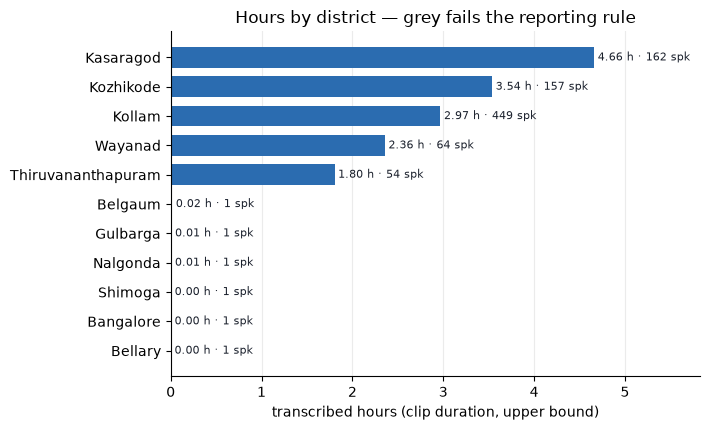

In [22]:
fig, ax = plt.subplots(figsize=(7.2, 4.4))
plot_df = district_summary.sort_values("hours")
colors = ["#2b6cb0" if ok else "#cbd5e0" for ok in plot_df.reportable]

ax.barh(plot_df.index, plot_df.hours, color=colors, height=0.7)
for y, (name, row) in enumerate(plot_df.iterrows()):
    ax.text(row.hours + 0.04, y, f"{row.hours:.2f} h · {int(row.speakers)} spk",
            va="center", fontsize=8, color="#1a202c")
ax.set_xlabel("transcribed hours (clip duration, upper bound)")
ax.set_xlim(0, plot_df.hours.max() * 1.25)
ax.set_title("Hours by district — grey fails the reporting rule")
ax.grid(axis="x", alpha=0.25)
ax.set_axisbelow(True)
for side in ("top", "right"):
    ax.spines[side].set_visible(False)
plt.tight_layout()
plt.show()

## 3. Noise tags

Two numbers are reported: the rate of **noise events** per hour (tags inside the transcript) and the share of utterances collected under a `<noise>` or `<static_noise>` label. They answer different questions — how often annotators marked a sound, versus how much of the corpus was recorded in noisy conditions — so they should not be added together. The inventory is deliberately unmerged: `[unintelligible]` and `[inaudible]` are annotator judgements rather than physical sound events, and a paper should say which of the 90 tag types it treats as noise.

In [23]:
total_hours = df.hours.sum()
noise_total = int(df.n_noise_events.sum())
rows_with_noise = int(df.has_noise_event.sum())
noise_condition_rows = int(df.noise_condition.sum())

print(f"Noise events: {noise_total:,} in {total_hours:.2f} h "
      f"({noise_total / total_hours:.1f} per hour)")
print(f"Utterances with >=1 noise event: {rows_with_noise:,} "
      f"({rows_with_noise / len(df):.1%}); mean per utterance {df.n_noise_events.mean():.2f}")
print(f"Utterances labelled <noise>/<static_noise>: {noise_condition_rows:,} "
      f"({noise_condition_rows / len(df):.1%})")
print(f"<pause> markers: {int(df.n_pause.sum()):,} "
      f"({df.n_pause.sum() / total_hours:.1f} per hour)")

noise_events = (
    df[["sample_id", "noise_types"]]
    .explode("noise_types")
    .dropna(subset=["noise_types"])
    .rename(columns={"noise_types": "tag"})
)
noise_tags = (
    noise_events.groupby("tag")
    .agg(events=("sample_id", "size"), rows=("sample_id", "nunique"))
    .reset_index()
)
noise_tags["per_hour"] = noise_tags.events / total_hours
noise_tags["share_rows_%"] = 100 * noise_tags.rows / len(df)
noise_tags["share_events_%"] = 100 * noise_tags.events / noise_total
noise_tags = noise_tags.sort_values("events", ascending=False)

display(noise_tags.head(20).round(2).reset_index(drop=True))

Noise events: 6,807 in 15.37 h (443.0 per hour)
Utterances with >=1 noise event: 4,121 (41.2%); mean per utterance 0.68
Utterances labelled <noise>/<static_noise>: 2,779 (27.8%)
<pause> markers: 3,200 (208.2 per hour)


,tag,events,rows,per_hour,share_rows_%,share_events_%
0,breathing,2739,2229,178.24,22.29,40.24
1,noise,518,434,33.71,4.34,7.61
2,unintelligible,443,412,28.83,4.12,6.51
3,bird_sound,420,367,27.33,3.67,6.17
4,talking,320,295,20.82,2.95,4.70
5,/bird_sound,251,247,16.33,2.47,3.69
6,/talking,236,230,15.36,2.30,3.47
7,lipsticks,221,196,14.38,1.96,3.25
8,horn,129,119,8.39,1.19,1.90
9,inhaling,127,111,8.26,1.11,1.87


### Noise and English rates, with speaker-level uncertainty

Each rate is computed on identified speakers only, in reportable districts. The 95% interval comes from a **cluster bootstrap that resamples speakers** (2,000 draws), not utterances: it answers "would this rate hold if we had drawn a different five-plus speakers from the same district?", which is the question created by the reporting rule.

In [24]:
def cluster_bootstrap_rate(frame, numerator, denominator, n_boot=2000, seed=0):
    # Pooled rate with a 95% interval from resampling whole speakers.
    per_speaker = frame.groupby("speaker_id")[[numerator, denominator]].sum()
    per_speaker = per_speaker[per_speaker[denominator] > 0]
    n = len(per_speaker)
    if n == 0:
        return np.nan, np.nan, np.nan, 0
    num = per_speaker[numerator].to_numpy(float)
    den = per_speaker[denominator].to_numpy(float)
    point = num.sum() / den.sum()
    if n < 2:
        return point, np.nan, np.nan, n
    rng = np.random.default_rng(seed)
    idx = rng.integers(0, n, size=(n_boot, n))
    boot = num[idx].sum(axis=1) / den[idx].sum(axis=1)
    lo, hi = np.percentile(boot, [2.5, 97.5])
    return point, lo, hi, n


def rate_table(frame, keys):
    rows = []
    for key, part in frame.groupby(keys[0] if len(keys) == 1 else keys):
        if not isinstance(key, tuple):
            key = (key,)
        n_hour, n_lo, n_hi, n_spk = cluster_bootstrap_rate(
            part, "n_noise_events", "hours"
        )
        e_100, e_lo, e_hi, _ = cluster_bootstrap_rate(
            part, "n_english", "words_per_100"
        )
        rec = dict(zip(keys, key))
        rec.update(
            speakers=n_spk,
            hours=part.hours.sum(),
            noise_per_hour=n_hour,
            noise_lo=n_lo,
            noise_hi=n_hi,
            english_per_100w=e_100,
            english_lo=e_lo,
            english_hi=e_hi,
        )
        rows.append(rec)
    return pd.DataFrame(rows)


known_reportable = df[
    (df.speaker_id != "UNKNOWN") & (df.district.isin(reportable_districts))
]
district_rates = rate_table(known_reportable, ["district"]).sort_values(
    "english_per_100w", ascending=False
)
display(district_rates.round(2).reset_index(drop=True))

gender_rates = rate_table(known_reportable, ["gender"]).sort_values("gender")
display(gender_rates.round(2).reset_index(drop=True))

,district,speakers,hours,noise_per_hour,noise_lo,noise_hi,english_per_100w,english_lo,english_hi
0,Kasaragod,162,2.69,409.47,363.50,458.49,16.83,15.81,17.92
1,Kozhikode,157,2.38,479.59,433.33,524.98,14.29,13.25,15.39
2,Kollam,449,2.00,489.69,439.22,538.81,14.03,13.14,14.96
3,Wayanad,64,1.78,437.13,382.28,494.86,13.88,12.27,15.54
4,Thiruvananthapuram,54,1.47,387.93,326.96,451.34,13.06,10.72,15.42


,gender,speakers,hours,noise_per_hour,noise_lo,noise_hi,english_per_100w,english_lo,english_hi
0,Female,504,6.14,443.68,413.61,472.42,14.49,13.65,15.28
1,Male,382,4.17,441.67,405.09,479.37,14.82,13.91,15.75


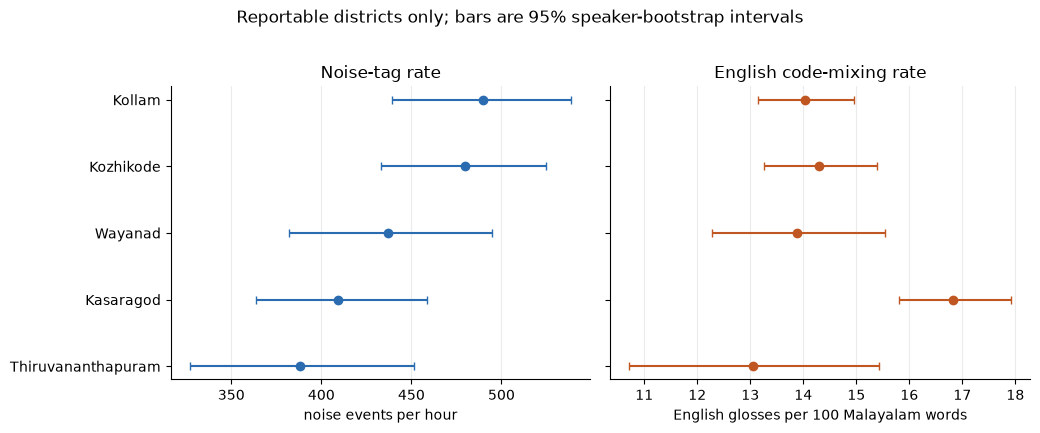

In [25]:
fig, axes = plt.subplots(1, 2, figsize=(10.5, 4.2), sharey=True)
plot_rates = district_rates.sort_values("noise_per_hour")
y = np.arange(len(plot_rates))

axes[0].errorbar(
    plot_rates.noise_per_hour, y,
    xerr=[plot_rates.noise_per_hour - plot_rates.noise_lo,
          plot_rates.noise_hi - plot_rates.noise_per_hour],
    fmt="o", color="#2b6cb0", capsize=3,
)
axes[0].set_yticks(y, plot_rates.district)
axes[0].set_xlabel("noise events per hour")
axes[0].set_title("Noise-tag rate")

axes[1].errorbar(
    plot_rates.english_per_100w, y,
    xerr=[plot_rates.english_per_100w - plot_rates.english_lo,
          plot_rates.english_hi - plot_rates.english_per_100w],
    fmt="o", color="#c05621", capsize=3,
)
axes[1].set_xlabel("English glosses per 100 Malayalam words")
axes[1].set_title("English code-mixing rate")

for ax in axes:
    ax.grid(axis="x", alpha=0.25)
    ax.set_axisbelow(True)
    for side in ("top", "right"):
        ax.spines[side].set_visible(False)
fig.suptitle("Reportable districts only; bars are 95% speaker-bootstrap intervals", y=1.02)
plt.tight_layout()
plt.show()

## 4. English glosses

`{…}` is the annotator's transliteration of an English word inside Malayalam speech, so this is a measure of **code-mixing**, not of English-language content. Rates use Malayalam words as the denominator; a per-hour version is included for convenience because speech rate varies by speaker.

In [26]:
english_events = (
    df[["sample_id", "english_terms"]]
    .explode("english_terms")
    .dropna(subset=["english_terms"])
    .rename(columns={"english_terms": "term"})
)
english_events["term_lower"] = english_events.term.str.lower()

eng_total = len(english_events)
eng_distinct = english_events.term_lower.nunique()
eng_rows = int(df.has_english.sum())
print(f"English glosses: {eng_total:,} tokens, {eng_distinct:,} distinct "
      f"(case-insensitive); {eng_rows:,} rows ({eng_rows / len(df):.1%})")
print(f"Rate: {100 * eng_total / df.n_ml_words.sum():.1f} per 100 Malayalam words; "
      f"{eng_total / total_hours:.1f} per hour")

top_terms = (
    english_events.groupby("term_lower")
    .agg(count=("sample_id", "size"), rows=("sample_id", "nunique"))
    .sort_values("count", ascending=False)
    .head(20)
)
display(top_terms)

English glosses: 15,533 tokens, 2,700 distinct (case-insensitive); 6,744 rows (67.4%)
Rate: 15.1 per 100 Malayalam words; 1010.8 per hour


,count,rows
term_lower,,
side,477,450
colour,349,285
car,326,271
building,320,275
shop,302,263
photo,252,238
road,221,195
board,219,204
school,212,171


## 5. Bottom line

The cell below prints the numbers that go into the paper's data section, so the prose does not have to be copied by hand from a table. It deliberately prints the weaknesses alongside the totals.

In [27]:
lines = []
lines.append(
    f"Rows {len(df):,} | transcribed audio {df.hours.sum():.2f} h "
    f"(clip duration, an upper bound on speech)."
)
lines.append(
    f"Identified speakers {known.speaker_id.nunique():,}; "
    f"{df.loc[df.speaker_id == 'UNKNOWN', 'hours'].sum() / df.hours.sum():.1%} "
    f"of hours have speaker_id UNKNOWN and are excluded from speaker-level rates."
)
lines.append(
    "Reportable districts (>={} speakers, >={:.0f} min): {}.".format(
        MIN_SPEAKERS, MIN_MINUTES, ", ".join(reportable_districts)
    )
)
lines.append(
    "Not reportable: " + "; ".join(
        f"{name} ({row.note})" for name, row in not_reportable.iterrows()
    ) + "."
)
lines.append(
    f"Noise events {noise_total:,} ({noise_total / total_hours:.1f}/h); "
    f"{rows_with_noise / len(df):.1%} of utterances carry at least one; "
    f"{noise_condition_rows / len(df):.1%} are labelled <noise>/<static_noise>."
)
lines.append(
    "Most frequent noise tags: " + ", ".join(
        f"{r.tag} ({int(r.events)})" for r in noise_tags.head(5).itertuples()
    ) + "."
)
lines.append(
    f"English glosses {eng_total:,} ({100 * eng_total / df.n_ml_words.sum():.1f} "
    f"per 100 Malayalam words) in {eng_rows / len(df):.1%} of utterances; "
    f"{eng_distinct:,} distinct types."
)
lines.append(
    "Most frequent English glosses: " + ", ".join(
        f"{t} ({int(c)})" for t, c in top_terms["count"].head(8).items()
    ) + "."
)
lines.append(
    f"Highest single-speaker share in a reportable district: "
    f"{district_summary.loc[reportable_districts, 'top_speaker_share'].max():.1%}."
)
print("\n".join("• " + line for line in lines))

• Rows 10,000 | transcribed audio 15.37 h (clip duration, an upper bound on speech).
• Identified speakers 892; 32.7% of hours have speaker_id UNKNOWN and are excluded from speaker-level rates.
• Reportable districts (>=5 speakers, >=30 min): Kasaragod, Kozhikode, Kollam, Wayanad, Thiruvananthapuram.
• Not reportable: Belgaum (only 1 speakers; only 1.0 min); Gulbarga (only 1 speakers; only 0.5 min); Nalgonda (only 1 speakers; only 0.4 min); Shimoga (only 1 speakers; only 0.2 min); Bangalore (only 1 speakers; only 0.2 min); Bellary (only 1 speakers; only 0.1 min).
• Noise events 6,807 (443.0/h); 41.2% of utterances carry at least one; 27.8% are labelled <noise>/<static_noise>.
• Most frequent noise tags: breathing (2739), noise (518), unintelligible (443), bird_sound (420), talking (320).
• English glosses 15,533 (15.1 per 100 Malayalam words) in 67.4% of utterances; 2,700 distinct types.
• Most frequent English glosses: side (477), colour (349), car (326), building (320), shop (302), p

In [28]:
exports = {
    "district_summary.csv": district_summary.reset_index(),
    "district_gender_summary.csv": cell_summary.reset_index(),
    "speaker_summary.csv": speaker_tbl.sort_values("minutes", ascending=False),
    "noise_tags.csv": noise_tags,
    "district_rates.csv": district_rates,
    "gender_rates.csv": gender_rates,
}
for name, table in exports.items():
    path = OUT_DIR / name
    table.to_csv(path, index=False)
    print(f"wrote {path.relative_to(ROOT)} ({len(table):,} rows)")

with open(OUT_DIR / "audit_params.json", "w", encoding="utf-8") as f:
    json.dump(
        {
            "repo_id": REPO_ID,
            "revision": REVISION,
            "rows": len(df),
            "hours": float(df.hours.sum()),
            "min_speakers": MIN_SPEAKERS,
            "min_minutes": MIN_MINUTES,
            "reportable_districts": reportable_districts,
        },
        f,
        indent=2,
    )
print("wrote", (OUT_DIR / "audit_params.json").relative_to(ROOT))

wrote build/e0_audit/district_summary.csv (11 rows)
wrote build/e0_audit/district_gender_summary.csv (16 rows)
wrote build/e0_audit/speaker_summary.csv (892 rows)
wrote build/e0_audit/noise_tags.csv (90 rows)
wrote build/e0_audit/district_rates.csv (5 rows)
wrote build/e0_audit/gender_rates.csv (2 rows)
wrote build/e0_audit/audit_params.json


## What this changes for E1 onward

- **Do not use the six Karnataka district labels as districts.** They total 17 rows across six labels; they are source-shard metadata, not a Malayalam sample. Either drop them or pool them as "other".
- **The UNKNOWN-speaker rows are a third of the hours.** District totals are fine for corpus description, but every speaker-level comparison (per-speaker error rates, speaker-disjoint splits, cluster bootstrap) is estimated on the identified subset. Quote the UNKNOWN share next to those results.
- **A district can pass the rule and still be concentrated.** Check `top_speaker_share` and `effective_speakers` before treating a district mean as a district property; the bootstrap intervals already resample speakers, so overlapping intervals are the honest signal.
- **E1:** build the test set from reportable district × gender cells, keep speakers disjoint between train and test, and keep the UNKNOWN rows out of any speaker-level split. If a cell has 5 speakers, it can enter the test set but its per-cell error rate will have a wide interval — report the interval or pool it.
- **E2/E3:** the noise tags and `{English}` glosses counted here are exactly the tokens the normalizers will strip or rewrite. Keep the raw transcripts untouched and derive normalized copies; otherwise the audit and the WER table will disagree about what was scored.
- **E4:** use the speaker-level rates saved in `build/e0_audit/` as covariates, not as ground truth about a district. The regression should include a per-speaker baseline, as planned.